# Model selection

When a method leaves one or more parameters open, there is not always a natural way to choose them – usually you simply have to try out what works best on the dataset in front of you.

For many real datasets several models are conceivable, and again there is not always a natural choice of the one likely to do best – here too, comparing different approaches is usually worth the effort.

There are various ways of assessing which model is 'better' than the others. We have already seen that overfitting can be a problem: simply comparing the number of correctly classified samples does not necessarily pick out the model that generalises best.

## Training, test and new data

The 'classical situation' in machine learning is this: while an ML system is being developed, you have access to data (the training data), which may already be labelled – that is, the desired output of the ML system is already part of the data.
Afterwards (once training is over) the system is supposed to work on newly arriving data – and those are not labelled.

Since unlabelled data give no way of judging how well the ML system has done, part of the labelled training data is set aside for that judgement – the test data. What distinguishes the test data from the 'real' data that come later is precisely that they are labelled.

We have already met `train_test_split` for this.

![Hyperparameter tuning](images/grid_search_workflow.png "Splitting the data in order to assess models")

(Figure from the [scikit-learn documentation](https://scikit-learn.org/stable/modules/cross_validation.html), BSD-3-Clause)

In [1]:
import numpy as np
from matplotlib import pyplot as plt
from sklearn.datasets import load_iris
x, y = load_iris(return_X_y=True)

### Training, validation and test

Suppose that, while developing an ML system, you compare 200 different variants by fitting each on the training set and analysing its performance on the test set. That inevitably produces an implicit fit to the test set, and hence an ML system that generalises badly. The test set is said to **leak** (information leakage).

To be able to compare variants and still keep a test set for judging how well the system works, the test set (or rather the training set) is split up further.

A typical setting: a competition withholds the target variable of the test set. To compare different models before the competition closes all the same, you can split off part of the training set as a validation set and keep it out of training.

The course *Introduction to Deep Learning* treats the train-test split, the validation set and the $k$-fold cross-validation of this chapter as known.

### k-fold cross-validation

Choosing a test set or a validation set brings two fundamental problems:

* you could be unlucky and end up with subsets of the data that are hardly representative
* less data for training will lead to worse results.

**k-fold cross-validation** tries to solve both problems by running the ML system several times – k times, to be precise – each time with a different split into training and test data. To do this, the training set is divided into k equal parts (called *folds*), and in the $i$-th of the $k$ runs the $i$-th part serves as the test set (and is left out of training).

This optimises for models that generalise well to unseen data.

In [2]:
from sklearn.model_selection import KFold

from sklearn.datasets import load_iris
x, y = load_iris(return_X_y=True)

cv = KFold(n_splits=3, shuffle=True, random_state=23)

for train_i, test_i in cv.split(x):
    print(test_i)
    test_x = x[test_i]
    test_y = y[test_i]
    print("mean of class label:", np.mean(y[test_i]))

[  2   3   5   7   9  10  16  17  18  19  20  24  28  30  34  44  45  46
  47  51  52  54  59  63  64  67  69  73  75  81  87  93  95  99 100 102
 106 113 115 120 122 125 126 131 133 135 137 139 140 146]
mean of class label: 0.94
[  1   4   8  11  23  26  27  29  33  37  42  50  53  55  61  62  68  70
  71  72  76  77  80  82  84  85  88  89  92  97 101 104 105 107 109 110
 111 112 114 117 119 121 127 128 130 132 134 136 142 148]
mean of class label: 1.18
[  0   6  12  13  14  15  21  22  25  31  32  35  36  38  39  40  41  43
  48  49  56  57  58  60  65  66  74  78  79  83  86  90  91  94  96  98
 103 108 116 118 123 124 129 138 141 143 144 145 147 149]
mean of class label: 0.88


### Stratified k-fold cross-validation

In the supervised learning setting – that is, when you have labelled training data – it can make sense for each individual 'fold' of the k-fold cross-validation to hold all the classes in representative proportions. This is called **stratified k-fold cross-validation**.

In [3]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

print("The following %d numbers should be quite similar:"
      % cv.get_n_splits())
for train_i, test_i in cv.split(x, y):
    print("mean of class label:", np.mean(y[test_i]))

The following 3 numbers should be quite similar:
mean of class label: 0.98
mean of class label: 1.0
mean of class label: 1.02


### Time-series-aware cross-validation

The cross-validation methods discussed so far assume that the data are independent and identically distributed – in particular, that every single sample is 'worth' as much as every other. If the data were collected over a period of time, however, that assumption is usually wrong. In many cases it can make sense to assume that past data have an influence on future data.

The naive approach would be to train on the first half of the data (in time) and use the second, later half as the test set.

```{admonition} Example
A model that predicts the mean surface temperature of the Earth from the concentrations of greenhouse gases in the atmosphere is fitted on the period 1800 to 2000 and then used to 'predict' the years 2000–2022, so that we can compare it with other models.
```

In scikit-learn you can use `TimeSeriesSplit`, which has the same syntax and semantics as `KFold` and `StratifiedKFold`; only the number of samples in the individual steps differs. There is also the integer parameter `gap`,
which sets how many samples to leave out at the end of each training set. With continuous data, this stops the data points at the end from 'knowing' too much about the data points that follow them in the test set.

### Visualising the cross-validation strategies

Extract [from the scikit-learn documentation](https://scikit-learn.org/stable/auto_examples/model_selection/plot_cv_indices.html#visualizing-cross-validation-behavior-in-scikit-learn) (BSD-3-Clause):

![KFold](images/sphx_glr_plot_cv_indices_006.png)

![StratifiedKFold](images/sphx_glr_plot_cv_indices_009.png)

![TimeSeriesSplit](images/sphx_glr_plot_cv_indices_013.png)


## Assessing model performance

We have already seen three essential approaches to assessing the quality of models:

* When the labels match – that is, when the model gives the classes $1,2,..$ with original labels $A,B,..$ those same labels $A,B,..$ and not, say, a permutation of them – we compared how often the model is right and how often wrong. That is what `sklearn.metrics.accuracy_score` does.
* When the labels are permuted (as we saw with k-means), we can work out which permutation gives the model the most 'correct' hits and work with that one (in effect undoing the permutation of the labels).
* When the labels are permuted, we can use a permutation-invariant score, such as the `normalized_mutual_info_score` $NMI$. As a reminder:

$$
NMI(U, V) = \dfrac{ I(U;V) }{ \texttt{mean}\big( H(U), H(V) \big) }, \qquad I(U;V) = H(U) + H(V) - H(U,V)
$$

with the *mutual information* $I(U;V)$ from the chapter [Relative entropy](relative-entropy.md): it is $0$ when the clustering and the classes have nothing to do with each other, and equals $H(U) = H(V)$ when either determines the other; the denominator normalises to $[0,1]$.

### Assessing a clustering

If the true classes are known, we can assess whether each cluster holds samples of a single class only, or how far the clustering departs from that (homogeneity), and whether all the samples of one class really do land in a single cluster:

In [4]:
from sklearn.cluster import KMeans

y_pred = KMeans().fit(x).predict(x)

from sklearn.metrics import homogeneity_score,\
                            completeness_score

print("Homogeneity:", homogeneity_score(y, y_pred))
print("Completeness:", completeness_score(y, y_pred))

Homogeneity: 0.9073325384241996
Completeness: 0.5331535221818433


Why is the completeness so poor in this example? Because we did not give KMeans a number of clusters, so it settles on more than 3:

In [5]:
print("Number of clusters:", np.max(y_pred)+1)
print("Number of classes:", np.max(y)+1)

Number of clusters: 8
Number of classes: 3


We now repeat this with $3$ clusters and watch the completeness rise while the homogeneity falls:

In [6]:
y_pred = KMeans(3).fit(x).predict(x)
assert np.max(y) == np.max(y_pred)

print("Homogeneity:", homogeneity_score(y, y_pred))
print("Completeness:", completeness_score(y, y_pred))

Homogeneity: 0.7514854021988338
Completeness: 0.7649861514489815


The harmonic mean (possibly weighted) of homogeneity and completeness is also called the **V-measure**, `v_measure_score`; one can show that it is equivalent to the normalised mutual information $NMI$.

Another way of summarising the classification quality of a clustering:

In [7]:
from sklearn.metrics import classification_report
print(classification_report(y, y_pred))

              precision    recall  f1-score   support

           0       0.00      0.00      0.00        50
           1       0.00      0.00      0.00        50
           2       0.23      0.28      0.25        50

    accuracy                           0.09       150
   macro avg       0.08      0.09      0.08       150
weighted avg       0.08      0.09      0.08       150



The columns of the `classification_report` are the summary measures from the chapter [Titanic EDA](titanic-eda-numpy.ipynb), only now one set per class instead of a single overall set: **precision** is the proportion of correct predictions among all predictions of that class, **recall** the proportion of instances recognised among all instances of that class, **f1-score** the harmonic mean of the two, and **support** the number of instances of the class in the ground truth. The rows underneath average over the classes, once unweighted (*macro avg*) and once weighted by support (*weighted avg*).

For a clustering these numbers have to be read with care: if the cluster holding the class *versicolor* happens to carry the number $2$, the report counts every one of those predictions as wrong, even though the clustering has found the class. The confusion matrix shows such a swap directly, as swapped rows:

[[ 0 50  0]
 [ 2  0 48]
 [36  0 14]]


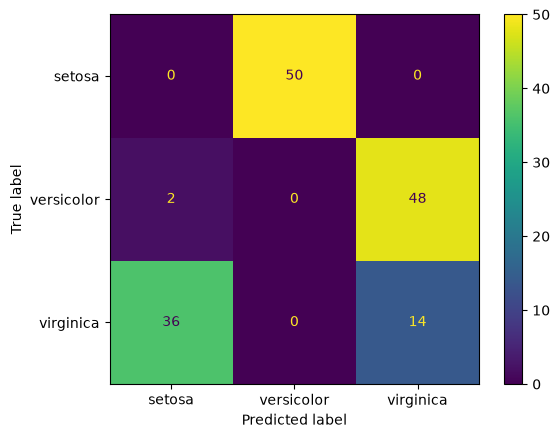

In [8]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

print(confusion_matrix(y, y_pred))
ConfusionMatrixDisplay.from_predictions(y, y_pred, display_labels=load_iris().target_names)
plt.show()

### Assessing a regression

A regression is assessed with the $R^2$ value, `r2_score`.

Despite what the name suggests, the $R^2$ value can perfectly well be negative; the formula is

$$
R^2 = 1 - \dfrac{\sum_i {\left(y_i - f(x_i, \beta)\right)}^2}{\sum_i {\left(y_i - \texttt{mean}(y)\right)}^2}
$$

If the model predicts the data perfectly, the numerator – the residual sum of squares – is $0$, and hence $R^2 = 1$.

The constant model that always returns $f(x_i, \beta) = \texttt{mean}(y)$ (and so is the best fit among all constant models) has $R^2 = 0$. Models that do worse – any other constant model, for example – have negative $R^2$ values.

## Hyperparameter search

Once you have worked out which estimators or methods you would like to use, which cross-validation you want and which scoring function is suitable, you still need a search strategy.

One possibility would be to pick two different hyperparameter settings at random and compare which performs better (in the sense of the chosen scoring function). Then pick two new ones at random near the better one, repeat, and so on.

```{admonition} Example
Hyperparameters are, for instance, the number of clusters in k-means (the k),
or the number of principal components to keep in PCA,
or the regularisation constant $\alpha$ of a linear regression,
or the regularisation parameter $C$ of an SVM,
or the parameters of the kernel in use,
such as the degree of a polynomial kernel.
```

### Grid search

If we want to optimise several parameters at once, one option would be to hold one parameter fixed, optimise the other, and then optimise the one we held fixed at first. Clearly, though, that does not reach an optimum in the 'loss landscape'. It is better to search all possible combinations of the two parameters.

As an example we take a kernel ridge regression with an RBF kernel (see the chapter Kernel methods) and search for the kernel width $\gamma$ and the regularisation $\alpha$. The regression task: predict the petal width of the Iris data from the other three features, scored with $R^2$. (The class labels $y$ would be the wrong target here: $0, 1, 2$ are categories, not numbers, and they call for classifiers and the scoring functions of the previous section.) Since both $\gamma$ and $\alpha$ can be sensible across several orders of magnitude, we lay out the grid logarithmically.

best parameters: {'alpha': np.float64(0.03125), 'gamma': np.float64(0.011288378916846888)}
r2 = 0.379506240834378


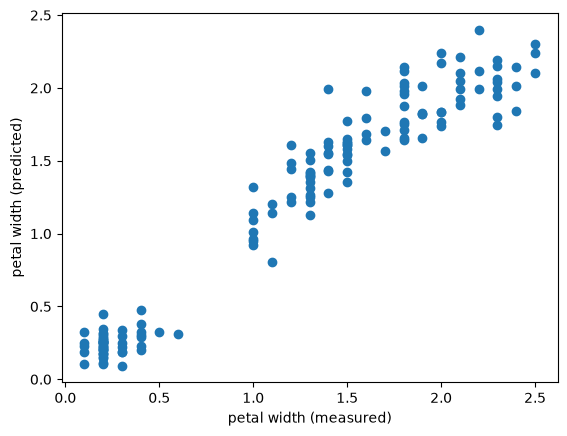

In [9]:
from sklearn.model_selection import GridSearchCV
from sklearn.kernel_ridge import KernelRidge

# regression: petal width (column 3) from the other three features
x_reg, y_reg = x[:, :3], x[:, 3]

reg = KernelRidge(kernel='rbf')

param_grid = {
    "gamma": np.logspace(-3, 1, num=20),
    "alpha": np.power(2, np.arange(-6, 5, dtype=float)),
}

grid_search = GridSearchCV(reg, param_grid=param_grid, scoring='r2')
grid_search.fit(x_reg, y_reg)

print("best parameters:", grid_search.best_params_)
print("r2 =", grid_search.best_score_)

est = grid_search.best_estimator_

fig, ax = plt.subplots()
ax.scatter(y_reg, est.predict(x_reg))
ax.set_xlabel("petal width (measured)")
ax.set_ylabel("petal width (predicted)")
plt.show()

### Randomised search

One can also examine pairs of parameters sampled at random from a given distribution.

best parameters: {'alpha': np.float64(0.015121396655907246), 'gamma': np.float64(0.006684141999245426)}
r2 = 0.37632841090763786


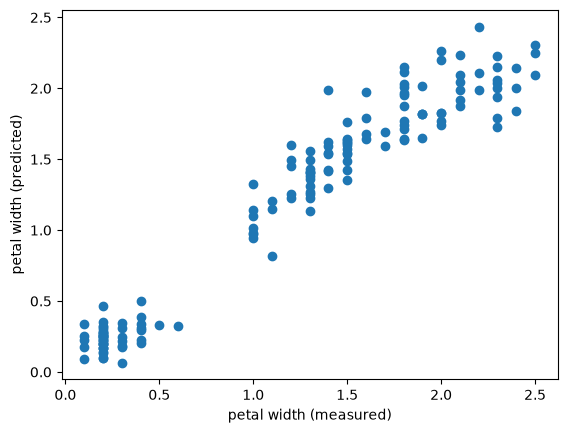

In [10]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform

param_dist = {
    "gamma": loguniform(1e-3, 1e1),
    "alpha": loguniform(1e-3, 1e0)
}

random_search = RandomizedSearchCV(
    reg,
    param_distributions=param_dist,
    n_iter=40
)

random_search.fit(x_reg, y_reg)

print("best parameters:", random_search.best_params_)
print("r2 =", random_search.best_score_)

est = random_search.best_estimator_

fig, ax = plt.subplots()
ax.scatter(y_reg, est.predict(x_reg))
ax.set_xlabel("petal width (measured)")
ax.set_ylabel("petal width (predicted)")
plt.show()

## An example application: Fashion MNIST

Every three rows form one class (T-shirts, trousers, and so on). The data come from [Zalando Research](https://github.com/zalandoresearch/fashion-mnist). The trouble with the classical 'handwritten digits' MNIST dataset is that it is a little too easy to classify correctly. Fashion-MNIST is meant as a drop-in replacement, a benchmark for ML algorithms to use instead of MNIST.

![Fashion MNIST](https://github.com/zalandoresearch/fashion-mnist/raw/master/doc/img/fashion-mnist-sprite.png)

In [11]:
from itertools import product
import numpy as np

# The loader lives in fashion_mnist.py (in the folder of these notes) and is also used in
# the chapters Expectation-Maximization and Model selection. The data are downloaded on the
# first call only and after that read from the working directory.
from fashion_mnist import load_mnist

In [12]:
x_train, y_train = load_mnist(kind='train')
x_test, y_test = load_mnist(kind='t10k')

We have to reduce the dimensionality, or training takes too long:

In [13]:
from sklearn.decomposition import PCA
pca = PCA(40).fit(x_train)
x_train_pc = pca.transform(x_train)
x_test_pc = pca.transform(x_test)

First, a look at the result of a support vector classification (SVC – a method we have not discussed and simply use as a black box here) without any hyperparameter fine-tuning:

In [14]:
from sklearn.svm import SVC

# trim down some more dimensions to speed this up:
pca2 = PCA(6).fit(x_train_pc)
x_train_pc2 = pca2.transform(x_train_pc)
x_test_pc2 = pca2.transform(x_test_pc)
svc = SVC().fit(x_train_pc2, y_train)
y_pred = svc.predict(x_test_pc2)

In [15]:
from sklearn.metrics import normalized_mutual_info_score
print(classification_report(y_test, y_pred))
print("NMI = %.2f" % normalized_mutual_info_score(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.74      0.79      0.76      1000
           1       0.94      0.85      0.90      1000
           2       0.65      0.55      0.60      1000
           3       0.69      0.81      0.75      1000
           4       0.62      0.65      0.63      1000
           5       0.86      0.84      0.85      1000
           6       0.43      0.39      0.41      1000
           7       0.85      0.84      0.84      1000
           8       0.93      0.94      0.93      1000
           9       0.86      0.90      0.88      1000

    accuracy                           0.76     10000
   macro avg       0.76      0.76      0.76     10000
weighted avg       0.76      0.76      0.76     10000

NMI = 0.67


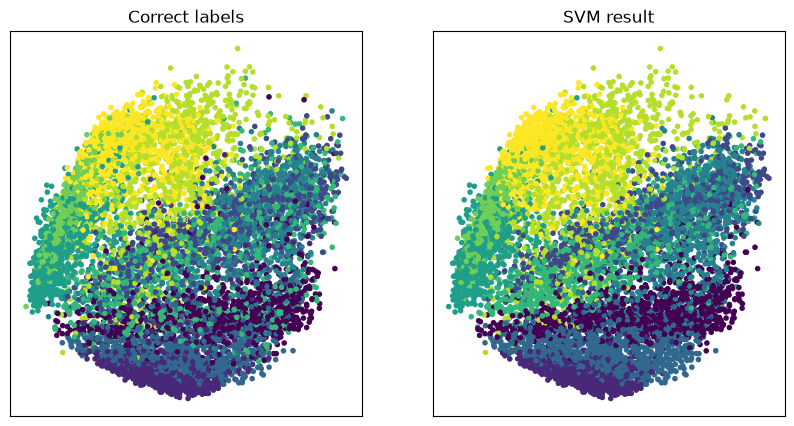

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(10, 5))
axs[0].scatter(x_test_pc2[:,0], x_test_pc2[:,1], c=y_test, marker='.')
axs[0].set_title("Correct labels")
axs[1].scatter(x_test_pc2[:,0], x_test_pc2[:,1], c=y_pred, marker='.')
axs[1].set_title("SVM result")
for ax in axs:
    ax.set_xticks([])
    ax.set_yticks([])
plt.show()

We can also visualise what the individual data points stand for:

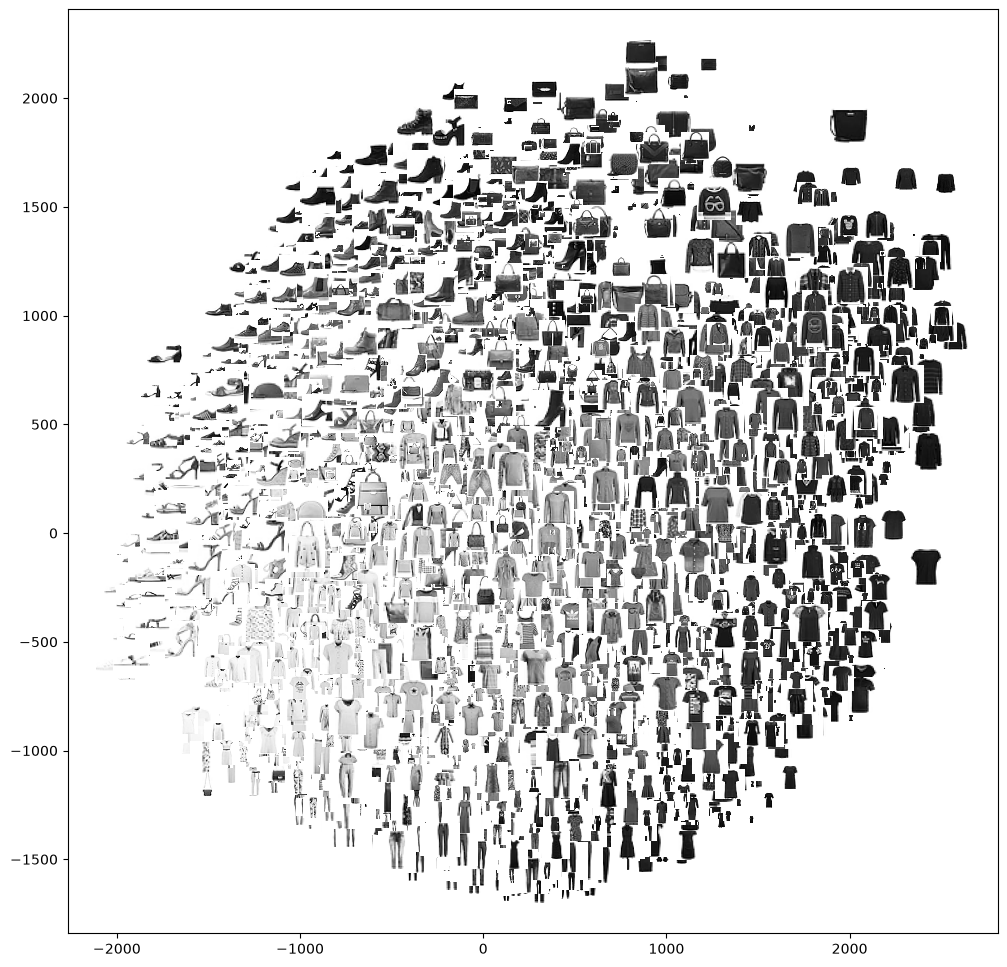

In [17]:
from matplotlib.offsetbox import OffsetImage, AnnotationBbox

def imscatter(x, y, image, ax, zoom=1):
    im = OffsetImage(image, zoom=zoom, norm=plt.Normalize(0,255), cmap="Greys")
    x, y = np.atleast_1d(x, y)
    artists = []
    for x0, y0 in zip(x, y):
        ab = AnnotationBbox(im, (x0, y0), xycoords='data', frameon=False)
        artists.append(ax.add_artist(ab))
    ax.update_datalim(np.column_stack([x, y]))
    ax.autoscale()
    return artists

fig, ax = plt.subplots(figsize=(12,12))
# plot every 2nd:
for i in range(0, len(x_test_pc2), 2):
    imscatter(x_test_pc2[i,0], x_test_pc2[i,1], x_test[i].reshape(28,28), ax, zoom=np.random.rand())
plt.show()

Now we look for good values of the hyperparameters $C, \gamma$ of the SVC. We go about it exactly as in the randomised search above:

* A subsample is enough for the search; training on all 60,000 images takes too long to be repeated dozens of times.
* $C$ and $\gamma$ can be sensible across many orders of magnitude, so we sample both log-uniformly.
* We scale the principal components to unit variance beforehand. Otherwise $\gamma$ has to make up for the enormous scale of the pixel sums and ends up at values around $10^{-8}$, which are hard to interpret. We put the scaling and the classifier into a `Pipeline`, so that in every fold of the cross-validation the scaling is estimated from that fold's training data alone.

In [18]:
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from scipy.stats import loguniform

dims = 12
small_x, _, small_y, _ = train_test_split(x_train_pc[:, :dims], y_train,
                                          train_size=2000, random_state=23)

pipe = make_pipeline(StandardScaler(), SVC())
param_dist = {
    "svc__C": loguniform(1e-1, 1e3),
    "svc__gamma": loguniform(1e-3, 1e0),
}
random_search = RandomizedSearchCV(pipe, param_distributions=param_dist,
                                   n_iter=40, cv=3, scoring='f1_macro',
                                   random_state=23, n_jobs=-1)
random_search.fit(small_x, small_y)
print("best parameters:", random_search.best_params_)
print("f1_macro (cross-validation on the subsample) =", random_search.best_score_)

best parameters: {'svc__C': np.float64(29.662611861688664), 'svc__gamma': np.float64(0.017210373067083652)}
f1_macro (cross-validation on the subsample) = 0.7899375300764434


How sensitive is the result to the parameters? A look at the best and the worst candidates:

In [19]:
import pandas as pd

results = pd.DataFrame(random_search.cv_results_)
results = results[["param_svc__C", "param_svc__gamma", "mean_test_score"]]
results = results.sort_values("mean_test_score", ascending=False)
print(results.head(5))
print(results.tail(3))

    param_svc__C  param_svc__gamma  mean_test_score
4      29.662612          0.017210         0.789938
1     115.302583          0.007034         0.787693
31    463.053198          0.005063         0.785714
12    587.036265          0.002658         0.784648
30    469.659620          0.002439         0.784420
    param_svc__C  param_svc__gamma  mean_test_score
5       0.102296          0.448845         0.539789
38      0.215727          0.001445         0.308637
11      0.276637          0.001004         0.242741


With the parameters found, we now train on all the samples. The pipeline re-estimates the scaling as it does so, this time from all the training data:

In [20]:
from sklearn.metrics import f1_score

best = random_search.best_estimator_     # pipeline with the best parameters
best.fit(x_train_pc[:, :dims], y_train)
y_pred = best.predict(x_test_pc[:, :dims])
print(f1_score(y_test, y_pred, average="macro"))

0.8362604024819902


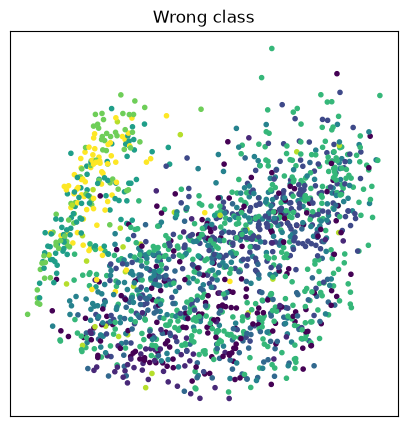

In [21]:
y_wrong_indices = (y_test != y_pred)
y_wrong = y_test[y_wrong_indices]
x_wrong = x_test_pc2[y_wrong_indices]

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(x_wrong[:,0], x_wrong[:,1], c=y_wrong, marker='.')
ax.set_title("Wrong class")
ax.set_xticks([])
ax.set_yticks([])
plt.show()

Can you manage a better classification (with an F1 score $> 0.85$)? Some ideas: more principal components, a larger subsample for the search, a different kernel, or an altogether different classifier.